In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display more columns when exploring the dataset
pd.set_option('display.max_columns', None)


In [3]:

from google.colab import files
import io

# Upload CSV file from your laptop
uploaded = files.upload()

# Read the uploaded dataset
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]), sep=";")

# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Display the first 5 rows
df.head()


Saving Zara_sales_EDA.csv to Zara_sales_EDA.csv
Dataset shape: (20252, 17)


,Product ID,Product Position,Promotion,Product Category,Seasonal,Sales Volume,brand,url,name,description,price,currency,terms,section,season,material,origin
0,185102,Aisle,Yes,clothing,Yes,1243,Zara,https://www.zara.com/us/en/basic-puffer-jacket...,BASIC PUFFER JACKET,Puffer jacket made of tear-resistant ripstop f...,78.99,USD,jackets,MAN,Winter,Polyester,Brazil
1,188771,Aisle,Yes,clothing,No,1429,Zara,https://www.zara.com/us/en/tuxedo-jacket-p0889...,TUXEDO JACKET,Straight fit blazer. Pointed lapel collar and ...,14.99,USD,jackets,MAN,Autumn,Cotton,Turkey
2,180176,End-cap,Yes,clothing,Yes,1168,Zara,https://www.zara.com/us/en/slim-fit-suit-jacke...,SLIM FIT SUIT JACKET,Slim fit jacket. Notched lapel collar. Long sl...,71.95,USD,jackets,WOMAN,Autumn,Polyester,Morocco
3,112917,Aisle,Yes,clothing,No,1348,Zara,https://www.zara.com/us/en/stretch-suit-jacket...,STRETCH SUIT JACKET,Slim fit jacket made of viscose blend fabric. ...,30.99,USD,jackets,MAN,Spring,Polyester,China
4,192936,End-cap,Yes,clothing,Yes,1602,Zara,https://www.zara.com/us/en/double-faced-jacket...,DOUBLE FACED JACKET,Jacket made of faux leather faux shearling wit...,22.99,USD,jackets,WOMAN,Winter,Wool Blend,China


In [5]:

# CELL 3: DATASET STRUCTURE

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

# FINDINGS:
# The dataset contains 20,252 observations and 17 variables.
# It includes both numerical and categorical features.
# Sales Volume is our target variable.
# Categorical features will require encoding before model training.

#Interpretation:Our dataset is large enough to support an initial machine learning analysis.
#We must examine the relevance of each variable before including it in our predictive models.


Dataset shape: (20252, 17)

Column names:
['Product ID', 'Product Position', 'Promotion', 'Product Category', 'Seasonal', 'Sales Volume', 'brand', 'url', 'name', 'description', 'price', 'currency', 'terms', 'section', 'season', 'material', 'origin']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20252 entries, 0 to 20251
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Product ID        20252 non-null  int64  
 1   Product Position  20252 non-null  object 
 2   Promotion         20252 non-null  object 
 3   Product Category  20252 non-null  object 
 4   Seasonal          20252 non-null  object 
 5   Sales Volume      20252 non-null  int64  
 6   brand             20252 non-null  object 
 7   url               20252 non-null  object 
 8   name              20251 non-null  object 
 9   description       20250 non-null  object 
 10  price             20252 non-null  float64
 11  cur

In [6]:

# CELL 4: DATA QUALITY CHECKS

print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing values (%):")
print(missing_percentage.round(2))

# FINDINGS:
# Only 3 missing values were identified:
# - 1 missing product name
# - 2 missing product descriptions
# No fully duplicated rows were detected.
# The dataset is relatively complete.
# Missing text fields should not significantly affect the model
# if these variables are excluded from the predictors.


Missing values per column:
Product ID          0
Product Position    0
Promotion           0
Product Category    0
Seasonal            0
Sales Volume        0
brand               0
url                 0
name                1
description         2
price               0
currency            0
terms               0
section             0
season              0
material            0
origin              0
dtype: int64

Number of duplicate rows:
0

Missing values (%):
Product ID          0.00
Product Position    0.00
Promotion           0.00
Product Category    0.00
Seasonal            0.00
Sales Volume        0.00
brand               0.00
url                 0.00
name                0.00
description         0.01
price               0.00
currency            0.00
terms               0.00
section             0.00
season              0.00
material            0.00
origin              0.00
dtype: float64


In [7]:

# =====================================================
# CELL 5: DESCRIPTIVE STATISTICS
# =====================================================

# Objective: Examine numerical and categorical variables.

print("Numerical Variables:")
display(df.describe())

print("\nCategorical Variables:")
display(df.describe(include=["object"]))

# KEY FINDINGS:
# Sales Volume ranges from approximately 518 to 1,940 units.
# Average Sales Volume is approximately 1,097 units.
# Product sales show considerable variability.


Numerical Variables:


,Product ID,Sales Volume,price
count,20252.000000,20252.000000,20252.000000
mean,208931.432303,1097.400454,41.949061
std,8961.076507,298.234609,23.380960
min,110075.000000,518.000000,12.000000
25%,204442.750000,849.000000,23.950000
50%,209505.500000,990.000000,35.950000
75%,214568.250000,1364.250000,53.950000
max,219631.000000,1940.000000,134.990000



Categorical Variables:


,Product Position,Promotion,Product Category,Seasonal,brand,url,name,description,currency,terms,section,season,material,origin
count,20252,20252,20252,20252,20252,20252,20251,20250,20252,20252,20252,20252,20252,20252
unique,3,2,1,2,1,228,17215,221,1,5,2,4,11,12
top,Aisle,No,clothing,No,Zara,https://www.zara.com/us/en/knit-sweater-with-r...,PLAID OVERSHIRT,Varsity jacket with elastic collar and long sl...,USD,jackets,WOMAN,Autumn,Cotton,China
freq,7810,11812,20252,10136,20252,187,8,333,20252,11232,13254,7665,3851,4026


Sales Volume Statistics:
count    20252.000000
mean      1097.400454
std        298.234609
min        518.000000
25%        849.000000
50%        990.000000
75%       1364.250000
max       1940.000000
Name: Sales Volume, dtype: float64


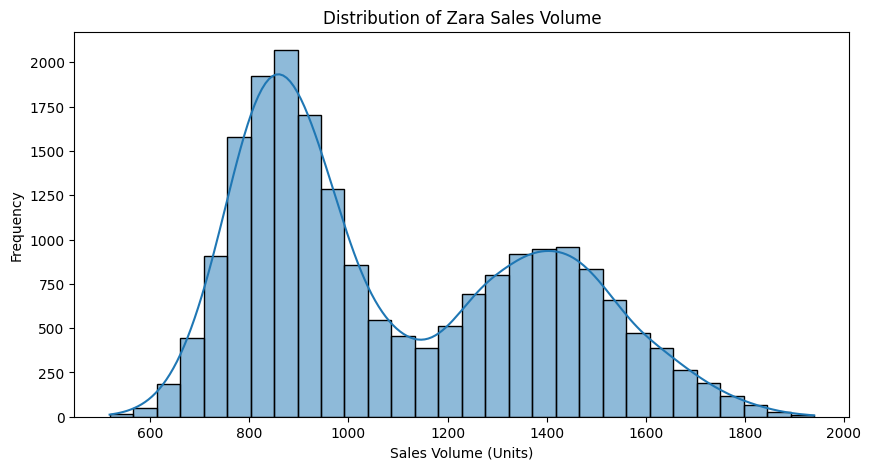

In [8]:

# =====================================================
# CELL 6: SALES VOLUME DISTRIBUTION
# =====================================================

# Objective: Analyze the distribution of our target
# variable and identify potential unusual values.

print("Sales Volume Statistics:")
print(df["Sales Volume"].describe())

# Visualize the distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales Volume",
    bins=30,
    kde=True
)

plt.title("Distribution of Zara Sales Volume")
plt.xlabel("Sales Volume (Units)")
plt.ylabel("Frequency")
plt.show()

# KEY FINDINGS:
# Sales volumes vary substantially across products.
# Compare the mean and median to assess possible skewness.
# Inspect the histogram for unusual values or clusters.


,count,mean,median,std
Promotion,,,,
No,11812,872.38,868.0,108.76
Yes,8440,1412.33,1406.0,163.77


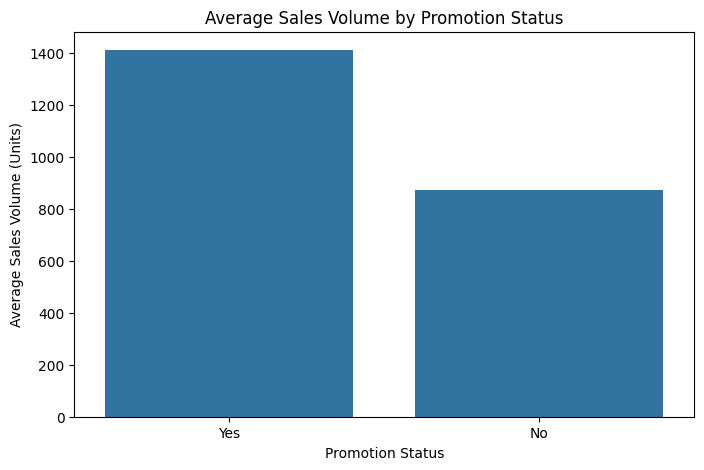


Average sales by promotion status:
Promotion
No      872.38
Yes    1412.33
Name: mean, dtype: float64


In [9]:


# CELL 7: PROMOTION STATUS VS. SALES VOLUME


# Objective: Compare sales performance between promoted
# and non-promoted Zara products.

# Calculate average sales volume by promotion status
promotion_sales = (
    df.groupby("Promotion")["Sales Volume"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(promotion_sales)

# Visualize average sales volume by promotion status
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Promotion",
    y="Sales Volume",
    estimator=np.mean,
    errorbar=None
)

plt.title("Average Sales Volume by Promotion Status")
plt.xlabel("Promotion Status")
plt.ylabel("Average Sales Volume (Units)")
plt.show()

# Calculate percentage difference between groups
if len(promotion_sales) == 2:
    avg_sales = promotion_sales["mean"]
    print("\nAverage sales by promotion status:")
    print(avg_sales)

# KEY FINDINGS:
# Compare the average sales volume of promoted and
# non-promoted products.
# Examine group sizes and sales variability.
# This comparison shows association, not causation.


Correlation between Price and Sales Volume:
-0.338


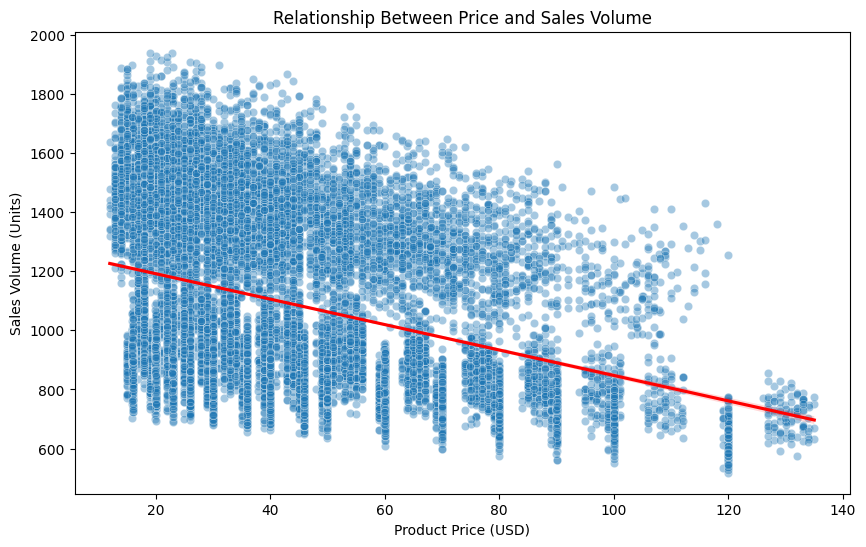

In [11]:

# CELL 8: PRICE VS. SALES VOLUME
# Objective: Examine the relationship between product
# price and sales volume.

# Calculate Pearson correlation
correlation = df["price"].corr(df["Sales Volume"])

print("Correlation between Price and Sales Volume:")
print(round(correlation, 3))

# Visualize the relationship
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="price",
    y="Sales Volume",
    alpha=0.4
)

# Add a linear trend line
sns.regplot(
    data=df,
    x="price",
    y="Sales Volume",
    scatter=False,
    color="red"
)

plt.title("Relationship Between Price and Sales Volume")
plt.xlabel("Product Price (USD)")
plt.ylabel("Sales Volume (Units)")
plt.show()

# KEY FINDINGS:
# The correlation coefficient measures the direction
# and strength of the linear relationship.
# A negative value suggests higher prices are associated
# with lower sales; a positive value suggests the opposite.
# The scatterplot helps identify patterns and outliers.


section
WOMAN    13254
MAN       6998
Name: count, dtype: int64


,count,mean,median
section,,,
WOMAN,13254,1136.35,1018.0
MAN,6998,1023.64,914.0


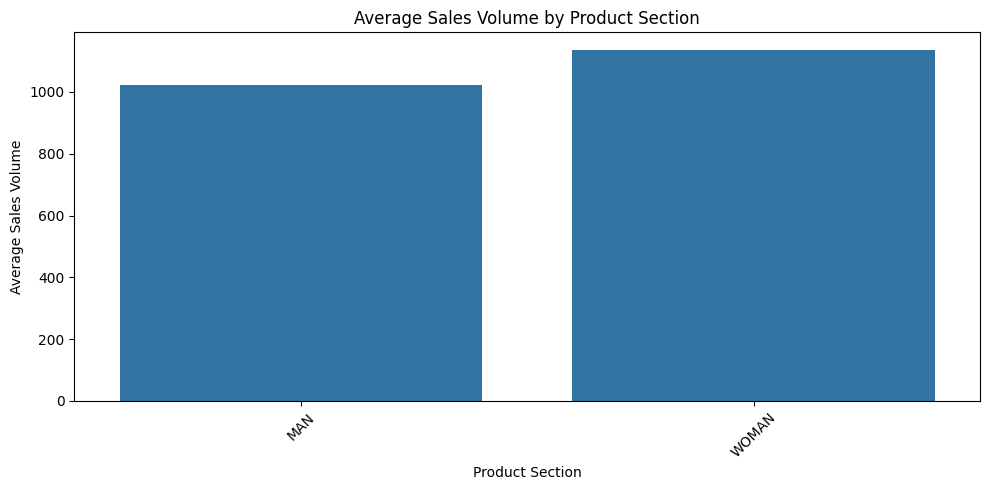

In [13]:

# Cell 9: Sales Volume by Product Section

# Check available product sections
print(df["section"].value_counts())

# Compare average sales volume by section
section_sales = (
    df.groupby("section")["Sales Volume"]
    .agg(["count", "mean", "median"])
    .sort_values(by="mean", ascending=False)
    .round(2)
)

display(section_sales)

# Visualize average sales volume
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="section",
    y="Sales Volume",
    estimator=np.mean,
    errorbar=None
)

plt.title("Average Sales Volume by Product Section")
plt.xlabel("Product Section")
plt.ylabel("Average Sales Volume")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key findings:
# Product Category contains only one value: clothing.
# Therefore, it cannot explain differences in sales volume.
# Product sections may provide more useful information.


season
Autumn    7665
Winter    5144
Spring    4537
Summer    2906
Name: count, dtype: int64


,count,mean,median
season,,,
Summer,2906,1184.59,1059.0
Winter,5144,1174.61,1046.0
Spring,4537,1046.22,928.0
Autumn,7665,1042.82,926.0


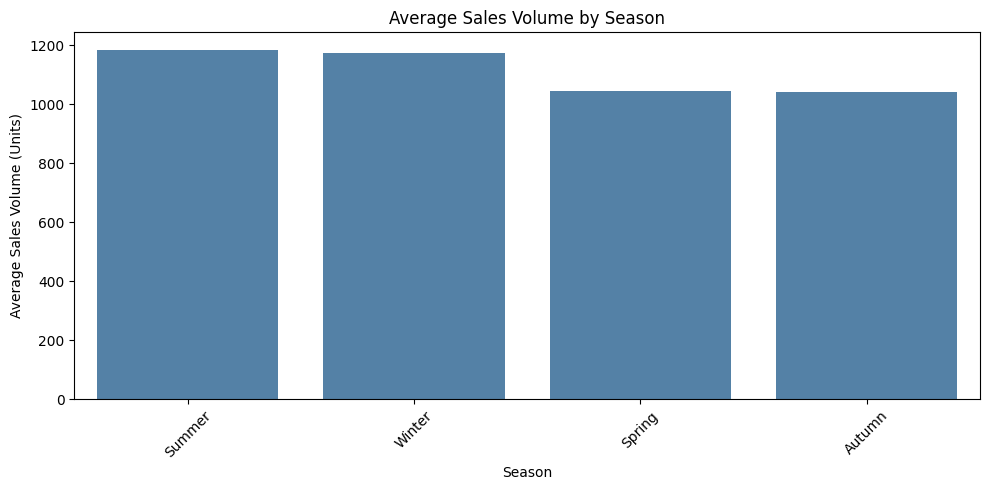

In [15]:

# Cell 10: Sales Volume by Season

# Check the number of products in each season
print(df["season"].value_counts())

# Calculate sales statistics by season
season_sales = (
    df.groupby("season")["Sales Volume"]
    .agg(["count", "mean", "median"])
    .sort_values(by="mean", ascending=False)
    .round(2)
)

display(season_sales)

# Visualize average sales volume by season
plt.figure(figsize=(10, 5))

sns.barplot(
    data=season_sales.reset_index(),
    x="season",
    y="mean",
    color="steelblue"
)

plt.title("Average Sales Volume by Season")
plt.xlabel("Season")
plt.ylabel("Average Sales Volume (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key findings:
# Compare average sales volumes across seasons.
# Identify which season records the highest average.
# Season may be a relevant predictor of sales volume.


,Price Range,Promotion,count,mean
0,"(11.999, 23.95]",No,2589,927.80
1,"(11.999, 23.95]",Yes,2511,1484.40
2,"(23.95, 35.95]",No,2859,912.19
3,"(23.95, 35.95]",Yes,2306,1445.00
4,"(35.95, 53.95]",No,3060,870.16
5,"(35.95, 53.95]",Yes,1903,1392.04
6,"(53.95, 134.99]",No,3304,796.55
7,"(53.95, 134.99]",Yes,1720,1285.74


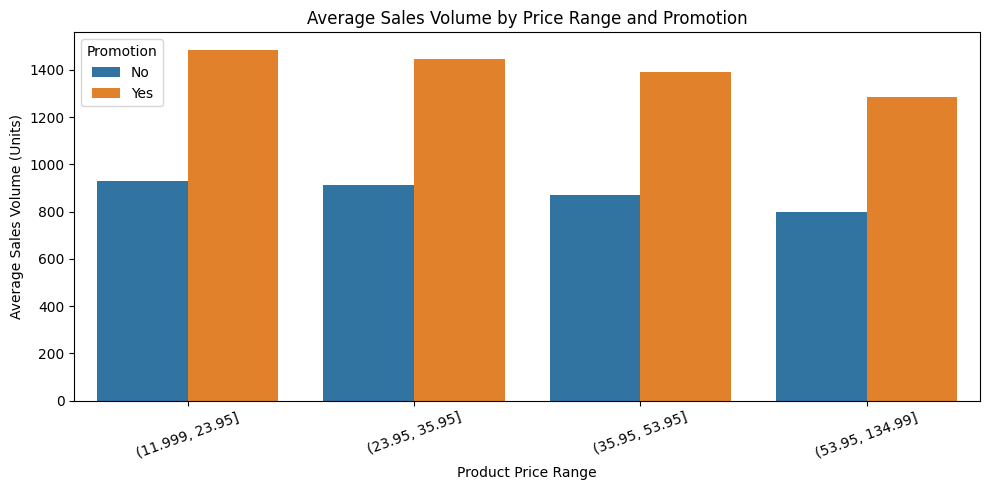

In [16]:

# Cell 10: Promotion and Price Analysis

# Create four price groups based on price quartiles
df["Price Range"] = pd.qcut(
    df["price"],
    q=4,
    duplicates="drop"
)

# Calculate sales statistics for each group
promotion_price = (
    df.groupby(["Price Range", "Promotion"], observed=True)
    ["Sales Volume"]
    .agg(["count", "mean"])
    .round(2)
    .reset_index()
)

display(promotion_price)

# Visualize average sales by price range and promotion
plt.figure(figsize=(10, 5))

sns.barplot(
    data=promotion_price,
    x="Price Range",
    y="mean",
    hue="Promotion"
)

plt.title("Average Sales Volume by Price Range and Promotion")
plt.xlabel("Product Price Range")
plt.ylabel("Average Sales Volume (Units)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Key findings:
# Compare promoted and non-promoted products within
# each price range.
# Identify whether the sales gap changes across price levels.
# Differences are descriptive, not causal promotion effects.


Promotion    No   Yes
section              
MAN        4112  2886
WOMAN      7700  5554


,section,Promotion,count,mean,median
0,MAN,No,4112,816.09,813.0
1,MAN,Yes,2886,1319.35,1309.0
2,WOMAN,No,7700,902.44,898.0
3,WOMAN,Yes,5554,1460.64,1454.0


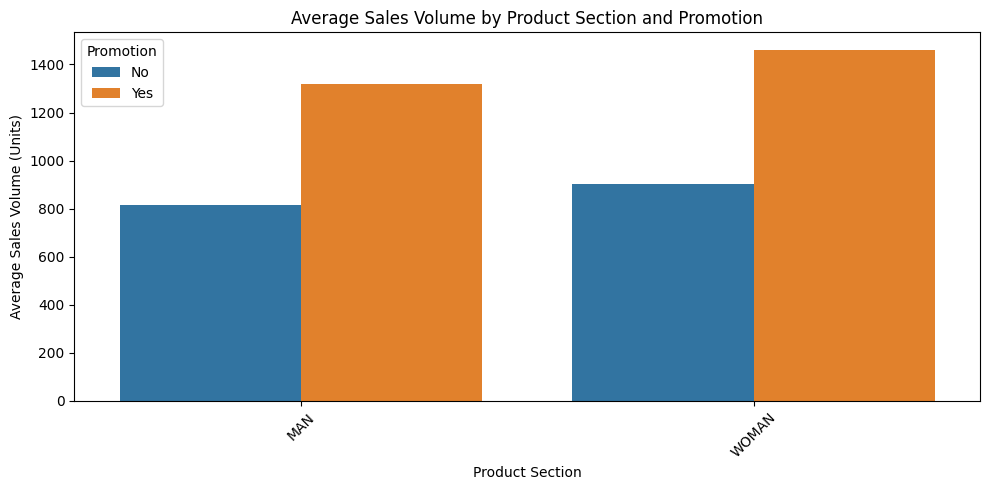

In [17]:

# Cell 11: Promotion and Product Section Analysis

# Check product sections and promotion distribution
print(pd.crosstab(df["section"], df["Promotion"]))

# Calculate sales statistics by section and promotion
promotion_section = (
    df.groupby(["section", "Promotion"])["Sales Volume"]
    .agg(["count", "mean", "median"])
    .round(2)
    .reset_index()
)

display(promotion_section)

# Visualize average sales volume
plt.figure(figsize=(10, 5))

sns.barplot(
    data=promotion_section,
    x="section",
    y="mean",
    hue="Promotion"
)

plt.title("Average Sales Volume by Product Section and Promotion")
plt.xlabel("Product Section")
plt.ylabel("Average Sales Volume (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key findings:
# Compare average sales of promoted and non-promoted
# products within each section.
# Check whether the promotional sales gap varies
# across sections.
# Consider group sizes when interpreting differences.


Promotion    No   Yes
season               
Autumn     4470  3195
Spring     2619  1918
Summer     1667  1239
Winter     3056  2088


,season,Promotion,count,mean,median
0,Autumn,No,4470,829.54,831.0
1,Autumn,Yes,3195,1341.22,1343.0
2,Spring,No,2619,829.70,829.0
3,Spring,Yes,1918,1341.89,1344.0
4,Summer,No,1667,935.46,936.0
5,Summer,Yes,1239,1519.78,1514.0
6,Winter,No,3056,937.21,940.0
7,Winter,Yes,2088,1522.08,1525.0


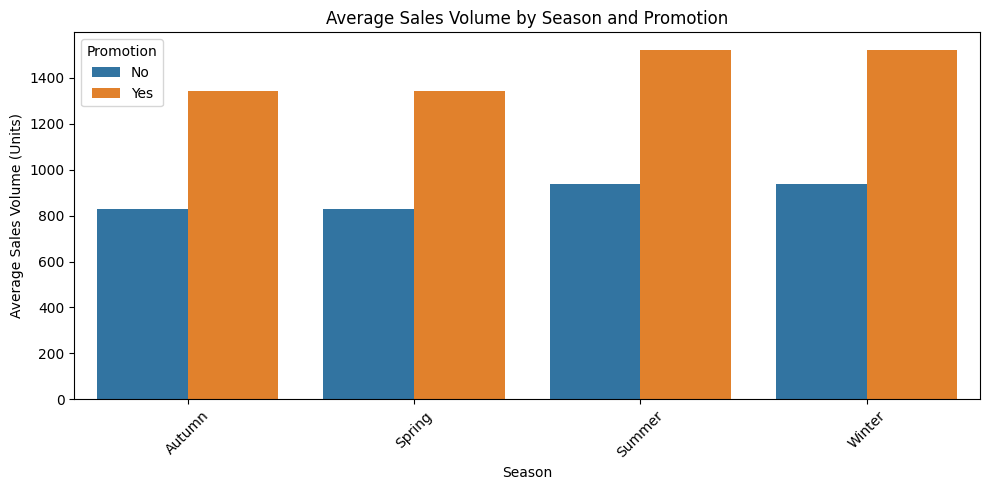

In [18]:

# Cell 12: Promotion and Season Analysis

# Check the distribution of promotions by season
print(pd.crosstab(df["season"], df["Promotion"]))

# Calculate sales statistics by season and promotion
promotion_season = (
    df.groupby(["season", "Promotion"])["Sales Volume"]
    .agg(["count", "mean", "median"])
    .round(2)
    .reset_index()
)

display(promotion_season)

# Visualize average sales volume
plt.figure(figsize=(10, 5))

sns.barplot(
    data=promotion_season,
    x="season",
    y="mean",
    hue="Promotion"
)

plt.title("Average Sales Volume by Season and Promotion")
plt.xlabel("Season")
plt.ylabel("Average Sales Volume (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key findings:
# Compare promoted and non-promoted sales within
# each season.
# Check whether promotional sales gaps differ by season.
# Consider group sizes before drawing conclusions.


In [19]:

# Cell 13: Feature Selection

# Define the target variable
y = df["Sales Volume"]

# Select relevant predictive features
selected_features = [
    "price",
    "Promotion",
    "Product Position",
    "Seasonal",
    "section",
    "season",
    "material",
    "terms"
]

# Create the feature dataset
X = df[selected_features].copy()

# Display selected features
print("Selected features:")
print(X.columns.tolist())

print("\nFeature dataset shape:", X.shape)
print("Target variable shape:", y.shape)

# Check feature data types
print("\nFeature data types:")
print(X.dtypes)

# Check missing values in selected features
print("\nMissing values:")
print(X.isnull().sum())

# Key findings:
# Sales Volume is the target variable.
# Eight candidate predictors have been selected.
# Constant variables, identifiers, URLs and text
# descriptions have been excluded.
# Feature usefulness will be evaluated during modeling.


Selected features:
['price', 'Promotion', 'Product Position', 'Seasonal', 'section', 'season', 'material', 'terms']

Feature dataset shape: (20252, 8)
Target variable shape: (20252,)

Feature data types:
price               float64
Promotion            object
Product Position     object
Seasonal             object
section              object
season               object
material             object
terms                object
dtype: object

Missing values:
price               0
Promotion           0
Product Position    0
Seasonal            0
section             0
season              0
material            0
terms               0
dtype: int64
